# 09 · Ablation studies

An ablation removes or changes **one** component at a time and measures the effect, with everything else fixed. It answers *why* the final model works, not just *that* it works. All runs use the same 5 engine folds, inner early-stopping engines and seed as notebooks 07–08, so differences come from the change alone.

| Group | Question |
|---|---|
| A. Branches | Does the hybrid need both its sequence branch and its feature branch? |
| B. Window length | Do longer histories (50, 80 cycles) help, as the Phase 1 gap analysis suggested? |
| C. Regularisation | What do dropout, weight decay, early stopping and input noise each contribute? |
| D. Padding mask | Does telling the model which steps are padding help? |

In [1]:
import sys
from pathlib import Path

REPO = "https://github.com/WhiteHacker000/Remaining-Useful-Life-Prediction-for-Industrial-Engines.git"

# On Google Colab only the notebook is opened, so clone the repository to get src/ and the data
if "google.colab" in sys.modules and not Path("../src").exists():
    import os, subprocess
    if not Path("/content/rul").exists():
        subprocess.run(["git", "clone", "-q", REPO, "/content/rul"], check=True)
    os.chdir("/content/rul/notebooks")

# Make the project folder importable (works from notebooks/ locally and on Colab)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import json
from dataclasses import replace
from src.config import RUL_CAP, RESULTS_DIR
from src.data import load_cmapss, add_train_rul
from src.evaluation import rmse
from src.models import engine_folds
from src.training import TrainConfig, run_cv
from src.plotting import set_style, save, BLUE, ORANGE, GREEN, GREY, INK, AQUA

set_style()
train, _, _ = load_cmapss("FD001")
train = add_train_rul(train)
DL = RESULTS_DIR / "dl"
cv08 = pd.read_csv(DL / "cv_hybrid_comparison.csv").set_index("model")
hyb = {e: json.loads((DL / f"cv_hybrid_{e}_w30.json").read_text()) for e in ["lstm", "tcn", "transformer"]}
enc = min(hyb, key=lambda e: hyb[e]["cv_rmse"])
seqs = {e: json.loads((DL / f"cv_{e}_w30.json").read_text()) for e in ["lstm", "tcn", "transformer"]}
base = TrainConfig(window=30)
print(f"reference model: hybrid with {enc.upper()} encoder, CV RMSE {hyb[enc]['cv_rmse']:.2f}")

reference model: hybrid with LSTM encoder, CV RMSE 9.55


In [2]:
RETRAIN = False
experiments = {
    # B. window length (hybrid and sequence-only)
    "hybrid, W = 50": (f"hybrid-{enc}", replace(base, window=50)),
    "hybrid, W = 80": (f"hybrid-{enc}", replace(base, window=80)),
    f"{enc.upper()} alone, W = 50": (enc, replace(base, window=50)),
    f"{enc.upper()} alone, W = 80": (enc, replace(base, window=80)),
    # C. regularisation (hybrid)
    "no dropout": (f"hybrid-{enc}", replace(base, dropout=0.0)),
    "no weight decay": (f"hybrid-{enc}", replace(base, weight_decay=0.0)),
    "no early stopping (60 epochs)": (f"hybrid-{enc}", replace(base, early_stopping=False)),
    "+ input noise (σ = 0.05)": (f"hybrid-{enc}", replace(base, noise_std=0.05)),
    # D. padding mask (hybrid)
    "no padding mask": (f"hybrid-{enc}", replace(base, use_mask=False)),
}
abl = {}
for label, (name, cfg) in experiments.items():
    key = "abl_" + "".join(ch if ch.isascii() and ch.isalnum() else "_" for ch in f"{name}_{label}").lower()
    abl[label] = run_cv(key, name, train, cfg, retrain=RETRAIN)[0]
    print(f"{label:32s} CV RMSE {abl[label]['cv_rmse']:.2f} ± {abl[label]['cv_std']:.2f}   ({abl[label]['minutes']} min)")

hybrid, W = 50                   CV RMSE 9.49 ± 0.42   (5.9 min)
hybrid, W = 80                   CV RMSE 9.51 ± 0.35   (43.81 min)
LSTM alone, W = 50               CV RMSE 11.87 ± 1.23   (3.39 min)
LSTM alone, W = 80               CV RMSE 12.46 ± 1.53   (5.45 min)
no dropout                       CV RMSE 9.67 ± 0.51   (1.84 min)
no weight decay                  CV RMSE 9.52 ± 0.53   (2.84 min)
no early stopping (60 epochs)    CV RMSE 9.20 ± 0.32   (6.56 min)
+ input noise (σ = 0.05)         CV RMSE 9.60 ± 0.81   (2.87 min)
no padding mask                  CV RMSE 9.74 ± 0.87   (2.26 min)


In [3]:
ref = np.array(hyb[enc]["fold_rmse"])
def delta_row(group, label, folds):
    folds = np.array(folds)
    d = folds - ref
    return {"group": group, "variant": label, "CV RMSE": folds.mean(), "change vs hybrid": d.mean(),
            "folds worse": int((d > 0).sum())}

seq_ref = np.array(seqs[enc]["fold_rmse"])
rows = [{"group": "reference", "variant": f"hybrid ({enc.upper()} + features, W = 30)", "CV RMSE": ref.mean(),
         "change vs hybrid": 0.0, "folds worse": 0}]
feat = json.loads((DL / "cv_features.json").read_text())
rows += [delta_row("A. branches", "remove sequence branch (features only)", feat["fold_rmse"]),
         delta_row("A. branches", "remove feature branch (sequence only)", seq_ref)]
rows += [delta_row("B. window", "W = 50", abl["hybrid, W = 50"]["fold_rmse"]),
         delta_row("B. window", "W = 80", abl["hybrid, W = 80"]["fold_rmse"])]
rows += [delta_row("C. regularisation", k, abl[k]["fold_rmse"])
         for k in ["no dropout", "no weight decay", "no early stopping (60 epochs)", "+ input noise (σ = 0.05)"]]
rows += [delta_row("D. mask", "no padding mask", abl["no padding mask"]["fold_rmse"])]
ablation = pd.DataFrame(rows).set_index(["group", "variant"])
ablation.to_csv(DL / "ablation_summary.csv")
ablation.round(2)

CV RMSE  \
group             variant                                           
reference         hybrid (LSTM + features, W = 30)           9.55   
A. branches       remove sequence branch (features only)    10.04   
                  remove feature branch (sequence only)     14.01   
B. window         W = 50                                     9.49   
                  W = 80                                     9.51   
C. regularisation no dropout                                 9.67   
                  no weight decay                            9.52   
                  no early stopping (60 epochs)              9.20   
                  + input noise (σ = 0.05)                   9.60   
D. mask           no padding mask                            9.74   

                                                          change vs hybrid  \
group             variant                                                    
reference         hybrid (LSTM + features, W = 30)                    0.00   
A. branches       remove sequence branch (features only)              0.49   
                  remove feature branch (sequence only)               4.46   
B. window         W = 50                                             -0.06   
                  W = 80                                             -0.04   
C. regularisation no dropout                                          0.12   
                  no weight decay                                    -0.03   
                  no early stopping (60 epochs)                      -0.36   
                  + input noise (σ = 0.05)                            0.05   
D. mask           no padding mask                                     0.18   

                                                          folds worse  
group             variant                                              
reference         hybrid (LSTM + features, W = 30)                  0  
A. branches       remove sequence branch (features only)            4  
                  remove feature branch (sequence only)             5  
B. window         W = 50                                            2  
                  W = 80                                            4  
C. regularisation no dropout                                        3  
                  no weight decay                                   2  
                  no early stopping (60 epochs)                     3  
                  + input noise (σ = 0.05)                          3  
D. mask           no padding mask                                   3

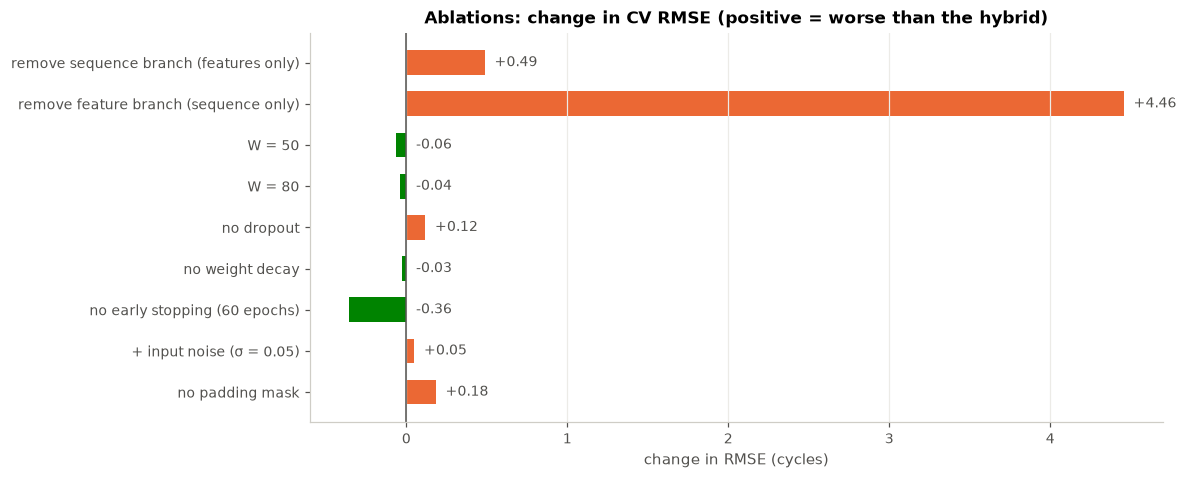

In [4]:
plot = ablation.drop(index="reference", level=0)
fig, ax = plt.subplots(figsize=(10, 4.6))
labels = [v for _, v in plot.index]
vals = plot["change vs hybrid"].values
ax.barh(labels[::-1], vals[::-1], color=[ORANGE if v > 0 else GREEN for v in vals[::-1]], height=0.6)
ax.axvline(0, color=INK, lw=1)
for i, v in enumerate(vals[::-1]):
    ax.text(max(v, 0) + 0.06, i, f"{v:+.2f}", va="center", ha="left", fontsize=9, color=INK)
ax.set(title="Ablations: change in CV RMSE (positive = worse than the hybrid)", xlabel="change in RMSE (cycles)")
ax.grid(axis="y", visible=False)
save(fig, "09_ablations")
plt.show()

Single-run changes are listed here. Section F shows that retraining the same configuration with another seed moves the CV RMSE by about **±0.5 to 0.7**, so only effects clearly larger than that should be trusted.

**A. Branches.** Removing the feature branch costs **+4.46** (worse on all 5 folds), far beyond the noise: the engineered features are the backbone. Removing the sequence branch costs +0.49 (worse on 4 of 5 folds). That is consistent, but of the same size as seed noise, so the value of the sequence branch rests on several pieces of evidence together: this ablation, the hybrid's lower error in every degradation stage on the test set (notebook 10), and the saliency analysis showing it uses different sensors.

**C. Regularisation.** Dropout (+0.12 without), weight decay (−0.03), input noise (+0.05) and the mask (D, +0.18) all change the error by less than the seed noise; we cannot claim any of them matters on its own here. A single run without early stopping was clearly better (9.20). Section F shows that most of that advantage survives over three seeds (9.73 vs 9.99 on average), and training also becomes steadier.

**Why early stopping hurt.** It watches only 7–8 inner-validation engines, so its signal is noisy and it stopped at epochs 14–30. Trained for the full 60 epochs, the hybrid's validation error ends within 0.05–0.4 of its best value on every fold, because dropout and the halving learning rate keep it stable. For the sequence-only models, early stopping remains necessary: their validation error turned up after 7–16 epochs (notebook 07).

### Window length: sequence model alone versus hybrid

Phase 1's gap analysis suggested longer histories should help. If that is true, the sequence model alone should gain more from a longer window than the hybrid, which already gets long-range context from its engineered features.

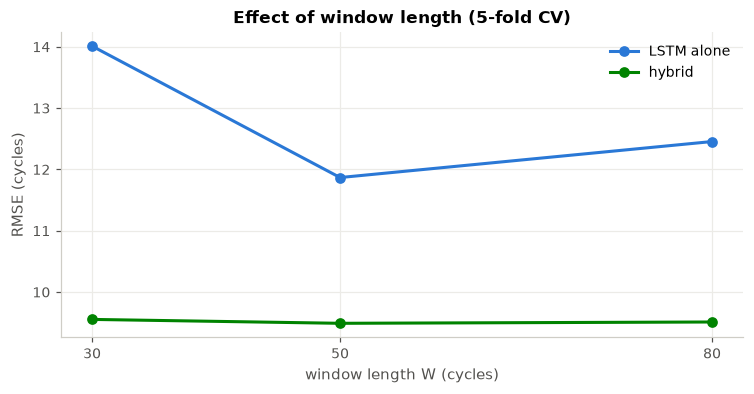

,LSTM alone,hybrid
window W,,
30,14.01,9.55
50,11.87,9.49
80,12.46,9.51


In [5]:
win = pd.DataFrame({
    f"{enc.upper()} alone": [seqs[enc]["cv_rmse"], abl[f"{enc.upper()} alone, W = 50"]["cv_rmse"], abl[f"{enc.upper()} alone, W = 80"]["cv_rmse"]],
    "hybrid": [hyb[enc]["cv_rmse"], abl["hybrid, W = 50"]["cv_rmse"], abl["hybrid, W = 80"]["cv_rmse"]]},
    index=pd.Index([30, 50, 80], name="window W"))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(win.index, win.iloc[:, 0], marker="o", color=BLUE, label=win.columns[0])
ax.plot(win.index, win["hybrid"], marker="o", color=GREEN, label="hybrid")
ax.set(title="Effect of window length (5-fold CV)", xlabel="window length W (cycles)", ylabel="RMSE (cycles)", xticks=[30, 50, 80])
ax.legend()
save(fig, "09_window_length")
plt.show()
win.round(2)

This is the clearest result of the ablations, and it confirms the Phase 1 gap analysis directly:

- The **LSTM alone gains a lot from a longer history**: 14.01 at W = 30, **11.87** at W = 50. Fixed short windows really do miss part of the degradation trajectory.
- The **hybrid hardly changes** (9.55, 9.49, 9.51): its engineered features already carry the long-range context (distance from the engine's first cycles, age), so a longer window adds little.
- W = 80 is worse than W = 50 for the LSTM alone: 38% of training cycles become partly padded, and an LSTM over 80 steps is harder to train. It is also 5–15 times slower; the hybrid at W = 80 took 44 minutes against 3 at W = 30.

We keep W = 30 for the hybrid: the same accuracy at a fraction of the cost.

### Regularisation: what overfitting looks like without it

The learning curves of the run without early stopping show what the regulariser prevents.

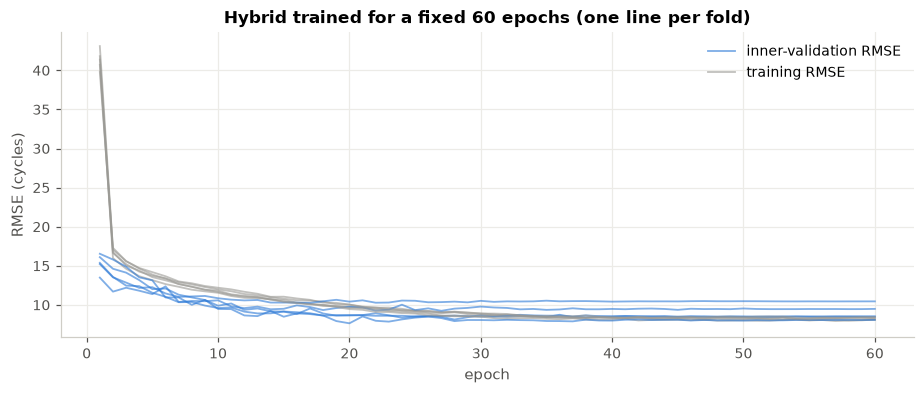

In [6]:
h = pd.DataFrame(abl["no early stopping (60 epochs)"]["history"])
fig, ax = plt.subplots(figsize=(10, 3.6))
for k, g in h.groupby("fold"):
    ax.plot(g["epoch"], g["val_rmse"], color=BLUE, alpha=0.6, lw=1.2, label="inner-validation RMSE" if k == 1 else None)
    ax.plot(g["epoch"], g["train_rmse"], color=GREY, alpha=0.6, lw=1.2, label="training RMSE" if k == 1 else None)
ax.set(title="Hybrid trained for a fixed 60 epochs (one line per fold)", xlabel="epoch", ylabel="RMSE (cycles)")
ax.legend()
save(fig, "09_no_early_stopping")
plt.show()

## E. Choosing the final configuration

Two changes improved the hybrid on their own: training for a fixed 60 epochs instead of early stopping, and input noise. We also train their combination, then **adopt the configuration with the lowest CV RMSE**. This is model selection on the CV folds only; the test set is still untouched.

In [7]:
combo_cfg = replace(base, early_stopping=False, noise_std=0.05)
combo = run_cv(f"cv_hybrid_{enc}_60ep_noise", f"hybrid-{enc}", train, combo_cfg, retrain=RETRAIN)[0]
candidates = {
    "default (early stopping)": hyb[enc],
    "60 epochs, no early stopping": abl["no early stopping (60 epochs)"],
    "early stopping + input noise": abl["+ input noise (σ = 0.05)"],
    "60 epochs + input noise": combo,
}
phase1 = pd.read_csv(RESULTS_DIR / "cv_oof_predictions.csv")
xgb = phase1[phase1["model"] == "XGBoost"]
folds = engine_folds(train["unit"])
xgb_f = np.array([rmse(np.minimum(xgb.loc[xgb["unit"].isin(f), "true_rul"], RUL_CAP), xgb.loc[xgb["unit"].isin(f), "pred"]) for f in folds])
sel = pd.DataFrame({k: {"CV RMSE": v["cv_rmse"], "± std": v["cv_std"],
                        "folds better than XGBoost": int((np.array(v["fold_rmse"]) < xgb_f).sum())}
                    for k, v in candidates.items()}).T
sel.loc["XGBoost, engineered (Phase 1)"] = [xgb_f.mean(), xgb_f.std(), np.nan]
chosen = sel.drop("XGBoost, engineered (Phase 1)")["CV RMSE"].idxmin()
sel.to_csv(DL / "final_configuration.csv")
print("chosen configuration:", chosen)
sel.round(2)

chosen configuration: 60 epochs, no early stopping


,CV RMSE,± std,folds better than XGBoost
default (early stopping),9.55,0.77,2.0
"60 epochs, no early stopping",9.20,0.32,2.0
early stopping + input noise,9.60,0.81,2.0
60 epochs + input noise,9.34,0.28,1.0
"XGBoost, engineered (Phase 1)",9.26,0.50,NaN


The fixed 60 epochs gives the lowest CV RMSE in a single run (9.20). Input noise did not help, alone (9.60) or combined (9.34). We adopt the 60-epoch configuration for the test set. Section F checks that this choice is not a fluke of one seed.

## F. How large must a difference be to be real?

Neural-network training is random (weight initialisation, batch order, dropout, which engines are held out for early stopping). On a multi-core CPU even the same seed does not give bit-identical results, because parallel floating-point sums are not always added in the same order. Re-running the input-noise ablation with an identical configuration gave **9.39** the first time and **9.60** the second. Before trusting any ablation, we therefore measure this noise directly: the reference hybrid and the chosen 60-epoch hybrid are each trained with two more seeds on the same folds.

In [8]:
seed_runs = {}
for label, cfg_ in [("default (early stopping)", base), ("60 epochs, no early stopping", replace(base, early_stopping=False))]:
    first = hyb[enc] if label.startswith("default") else abl["no early stopping (60 epochs)"]
    scores = [first["cv_rmse"]]
    tag = "default" if label.startswith("default") else "60ep"
    for s in (1, 2):
        scores.append(run_cv(f"seed_hybrid_{enc}_{tag}_s{s}", f"hybrid-{enc}", train, cfg_, seed=s, retrain=RETRAIN)[0]["cv_rmse"])
    seed_runs[label] = scores
noise_first = json.loads((DL / "abl_hybrid_lstm_input_noise_first_run.json").read_text())["cv_rmse"]
seeds = pd.DataFrame(seed_runs, index=["seed 42", "seed 1", "seed 2"]).T
seeds["mean"] = seeds.mean(axis=1)
seeds["std across seeds"] = seeds.iloc[:, :3].std(axis=1, ddof=1)
seeds.to_csv(DL / "seed_variability.csv")
print(f"input-noise ablation, identical configuration: first run {noise_first:.2f}, second run {abl['+ input noise (σ = 0.05)']['cv_rmse']:.2f}")
seeds.round(2)

input-noise ablation, identical configuration: first run 9.39, second run 9.60


,seed 42,seed 1,seed 2,mean,std across seeds
default (early stopping),9.55,10.81,9.61,9.99,0.71
"60 epochs, no early stopping",9.20,10.27,9.71,9.73,0.54


**This is the most important caveat of the whole comparison.**

- The default hybrid scores 9.55, 10.81 and 9.61 with three seeds (mean **9.99 ± 0.71**). The 60-epoch hybrid scores 9.20, 10.27 and 9.71 (mean **9.73 ± 0.54**). The single-run 9.20 was a favourable seed.
- The **60-epoch choice holds up**: it is better on average (by 0.26) and steadier across seeds, so adopting it was justified.
- Averaged over seeds, the hybrid's CV RMSE (9.7) is **slightly behind XGBoost** (9.26, which is deterministic for a fixed setting). On the official test set, with the three seeds averaged into one prediction, the two are statistically level (notebook 10).
- **Rule of thumb for this project:** differences below about 0.5 cycles of CV RMSE are within training noise. The clearly real effects are the feature branch (+4.46), the longer window for the LSTM alone (−2.1), and the gap between sequence-only networks and engineered features (4 to 6 cycles).

## Summary

| Question | Answer |
|---|---|
| Does the hybrid need both branches? | The features clearly (+4.46 without them); the sequence branch adds +0.49, consistent across folds but of the size of seed noise |
| Do longer windows help? | For the LSTM alone, a lot (14.0 → 11.9 at W = 50), confirming the Phase 1 gap; for the hybrid, no |
| Which regularisers matter? | at this data size, individual effects are within seed noise; early stopping on 7–8 engines stopped too early for the hybrid |
| How noisy is a CV score? | about ±0.5–0.7 across seeds, so only larger differences are trusted |
| Final configuration | LSTM hybrid, W = 30, a fixed 60 epochs: 9.73 ± 0.54 CV RMSE over three seeds |